# Test: CCF of the disc-integrated spectrum vs CCF mode (raw CCFs)

The quiet Sun computed in two ways, which should give the same CCF:

1. **Spectrum first.** The spectrum of every cell of the disc (MURaM high resolution spectra interpolated at the μ of the cell and Doppler shifted by its rotation velocity: `flux_grid(..., mode='spectroscopy', stellar_rotation=True)`), summed into the **disc-integrated spectrum**, whose CCF is computed with the line mask.
2. **CCF mode.** The same spectra in `CCF_grid`: the CCF of the spectrum of every ring (rest frame), then `StarSim(mode=['ccf'])` shifts the CCF of every cell by its rotation velocity and adds them.

**All the CCFs are raw** (`normalization='none'`): the CCF is minus the mask-weighted sum of the fluxes, in the units of the spectra, never normalised or rescaled. The CCF is linear in the spectrum, so the raw CCF of every ring keeps the brightness of the ring at every line (limb darkening, at every wavelength), and both paths weight a cell by its projected area / 4π: the two CCFs can be compared directly, without any weight or factor.

Full MURaM spectrum (3800-8000 Å, all the lines of the HARPS G2 mask inside it), converted from vacuum to air as the mask (`CCF_grid(..., spectrum_medium='air')`: by default `CCF_grid` converts vacuum spectra itself, which the spectrum-first path does not do: the two paths must get the same wavelengths), 10 rings, the Sun: equatorial period 24.47 d, solar differential rotation, inclination 7.25°, 1 R☉.

In [1]:
from sunsim import local_path   # paths of this computer: local_paths.ini (see local_paths.example.ini)
import os
os.environ.setdefault('KMP_WARNINGS', '0')
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sunsim import StarSim, SOLAR_DIFFERENTIAL_ROTATION, flux_grid, CCF_grid, mask_weights, nbspectra, vacuum2air

# star: the Sun
rotation_period = 24.47                         # [days] at the equator
differential_rotation = SOLAR_DIFFERENTIAL_ROTATION
inclination = np.deg2rad(7.25)                  # [rad] (0 = equator-on)
stellar_radius = 1.0                            # [solar radii]
N_rings = 10                                    # the spectra of the ~230 cells of the whole spectrum take ~0.8 GB
RAW = 2                                         # nbspectra.cross_correlation_mask: no normalisation

# MURaM high resolution spectra of the quiet Sun at 10 mu: the full spectrum, wavelengths converted from vacuum to air (the mask is in air)
muram_file = str(local_path('muram_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy')
raw = np.load(muram_file, allow_pickle=True).item()
spectra = {float(mu): {'wav': vacuum2air(np.asarray(d['wav'], dtype=np.float64)), 'intensity': np.asarray(d['intensity'], dtype=np.float64)}
           for mu, d in raw.items()}
del raw
wav = spectra[1.0]['wav']

# all the mask lines inside the spectrum (with a margin of 1 A for the Doppler shifts), velocity grid
wvm_all, fm_all = mask_weights(str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'))
keep = (wvm_all > wav[0] + 1) & (wvm_all < wav[-1] - 1)
wvm, fm = wvm_all[keep], fm_all[keep]
rv = 1000 * np.arange(-20, 20.25, 0.25)        # [m/s]
vsini = 2 * np.pi * stellar_radius * 6.957e8 / (rotation_period * 86400) * np.cos(inclination)
print('%d mu angles, %d wavelengths (%.0f-%.0f A), %d mask lines; vsini = %.0f m/s'
      % (len(spectra), len(wav), wav[0], wav[-1], len(wvm), vsini))

10 mu angles, 499998 wavelengths (3799-7998 A), 3492 mask lines; vsini = 2051 m/s


## 1. Spectrum first: disc-integrated spectrum, then its raw CCF

In [2]:
def disc_spectrum(rotation, spec=None):
    # disc-integrated spectrum: sum of the spectra of all the cells (Doppler shifted if rotation), whole spectrum
    spec = spectra if spec is None else spec
    w = spec[1.0]['wav']
    g = flux_grid(N_rings, spec, 'quiet', None, w[0], w[-1], rotation_period=rotation_period, inclination=inclination,
                  stellar_radius=stellar_radius, stellar_rotation=rotation, mode='spectroscopy',
                  differential_rotation=differential_rotation)
    g.built_grid()
    out = g.wv, g.disc_spectrum                 # wavelengths (shortened at both ends with rotation), spectrum
    del g
    return out

t0 = time.perf_counter()
disc = {'rotation': disc_spectrum(True), 'no rotation': disc_spectrum(False)}
ccf_spectrum = {k: nbspectra.cross_correlation_mask(rv, w, f, wvm, fm, False, RAW) for k, (w, f) in disc.items()}
print('disc-integrated spectra and their CCFs: %.1f s' % (time.perf_counter() - t0))

disc-integrated spectra and their CCFs: 0.4 s


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


## 2. CCF mode with the same spectra (raw CCFs)

`CCF_grid(..., normalization='none')` with the 10 spectra and no `mu_ratio`: the spectrum of every ring is interpolated at its μ (`interpolation='spectrum'`, as `flux_grid` does) and its raw CCF computed, so the brightness of every ring at every line is in its CCF. No bisector is added. Then `StarSim(mode=['ccf'])` with the same star, no active region, one epoch.

In [3]:
def ccf_mode(rotation, interpolation='spectrum', spec=None, rvs=rv):
    spec = spectra if spec is None else spec
    g = CCF_grid(N_rings, spec, rvs, wvm, fm, normalization='none', interpolation=interpolation, spectrum_medium='air')
    g.built_grid(bisector=None)
    ss = StarSim(np.array([0.0]), N_rings, inclination=inclination,
                 rotation_period=rotation_period if rotation else 1e12,     # no rotation: an extremely long period
                 differential_rotation=differential_rotation if rotation else 0, stellar_radius=stellar_radius,
                 active_regions_map=[], mode=['ccf'], ccf_grid_qp=g, ccf_grid_sp=g, ccf_grid_fc=g)
    ss.generate_timeseries(verbose=False)
    return ss

t0 = time.perf_counter()
runs = {'rotation': ccf_mode(True), 'no rotation': ccf_mode(False), "rotation, interpolation='ccf'": ccf_mode(True, 'ccf')}
ccf_ccfmode = {k: ss.ccf_var[0] for k, ss in runs.items()}
print('CCF mode: %.1f s' % (time.perf_counter() - t0))

CCF mode: 0.2 s


## 3. Comparison of the raw CCFs and of their bisectors

The raw CCFs are compared as they are (the same units, no rescaling). RV, FWHM, contrast and BIS are measured with the same fit (`StarSim.compute_ccf_params`, a gaussian with a free offset, and the bisector) on the raw CCFs.

In [4]:
fitter = runs['rotation']
pairs = {'rotation': ('rotation', 'rotation'), 'no rotation': ('no rotation', 'no rotation'),
         "rotation, CCF mode with interpolation='ccf'": ('rotation', "rotation, interpolation='ccf'")}
rows, fits = [], {}
for name, (ks, kc) in pairs.items():
    a, c = ccf_spectrum[ks], ccf_ccfmode[kc]
    fits[name] = fitter.compute_ccf_params(rv=rv, ccf=[a, c])
    r, contrast, fwhm, BIS = fits[name][:4]
    for k, label in enumerate(('spectrum first', 'CCF mode')):
        rows.append({'case': name, 'method': label, 'RV [m/s]': r[k], 'FWHM [m/s]': fwhm[k], 'contrast': contrast[k],
                     'BIS [m/s]': BIS[k]})
    rows.append({'case': name, 'method': 'difference', 'RV [m/s]': r[1] - r[0], 'FWHM [m/s]': fwhm[1] - fwhm[0],
                 'contrast': contrast[1] - contrast[0], 'BIS [m/s]': BIS[1] - BIS[0],
                 'max |CCF difference| / depth of the CCF': np.max(np.abs(c - a)) / np.ptp(a)})
pd.options.display.float_format = '{:.5g}'.format
pd.DataFrame(rows).set_index(['case', 'method'])

RV [m/s]  \
case                                        method                      
rotation                                    spectrum first    -982.63   
                                            CCF mode          -982.58   
                                            difference       0.048813   
no rotation                                 spectrum first    -976.73   
                                            CCF mode          -976.73   
                                            difference     1.3386e-07   
rotation, CCF mode with interpolation='ccf' spectrum first    -982.63   
                                            CCF mode          -981.99   
                                            difference        0.63833   

                                                            FWHM [m/s]  \
case                                        method                       
rotation                                    spectrum first      6866.7   
                                            CCF mode            6857.8   
                                            difference          -8.937   
no rotation                                 spectrum first      6554.2   
                                            CCF mode            6554.2   
                                            difference      4.7078e-07   
rotation, CCF mode with interpolation='ccf' spectrum first      6866.7   
                                            CCF mode            6859.2   
                                            difference         -7.5317   

                                                             contrast  \
case                                        method                      
rotation                                    spectrum first  0.0036859   
                                            CCF mode         0.003691   
                                            difference     5.0787e-06   
no rotation                                 spectrum first  0.0038931   
                                            CCF mode        0.0038931   
                                            difference     1.0933e-14   
rotation, CCF mode with interpolation='ccf' spectrum first  0.0036859   
                                            CCF mode        0.0036965   
                                            difference      1.058e-05   

                                                            BIS [m/s]  \
case                                        method                      
rotation                                    spectrum first    -44.879   
                                            CCF mode          -45.058   
                                            difference       -0.17846   
no rotation                                 spectrum first    -58.869   
                                            CCF mode          -58.869   
                                            difference     9.5156e-11   
rotation, CCF mode with interpolation='ccf' spectrum first    -44.879   
                                            CCF mode          -44.831   
                                            difference        0.04842   

                                                            max |CCF difference| / depth of the CCF  
case                                        method                                                   
rotation                                    spectrum first                                      NaN  
                                            CCF mode                                            NaN  
                                            difference                                    0.0013585  
no rotation                                 spectrum first                                      NaN  
                                            CCF mode                                            NaN  
                                            difference                                   2.8377e-13  
rotation, CCF mode

## 4. With rotation: the interpolation of the Doppler shifts

The rotation velocities of the cells are the same in both paths (`flux_grid.vrel` = `StarSim.rvel`), but the Doppler shift of every cell is a **linear interpolation**: of the spectrum in (1), on the MURaM grid (0.01 Å, 0.0060 Å below 5000 Å), and of the CCF in (2), on the velocity grid (250 m/s). A linear interpolation at a fraction of a pixel smooths the profile (it adds ~h²/6 to its variance, h = step). The check refines the two grids: the spectra resampled at 0.005 Å (cubic spline, for both paths) and the velocity grid at 250 and 50 m/s.

In [5]:
from scipy.interpolate import CubicSpline

def resampled(step):
    # the spectra on a finer wavelength grid (cubic spline), the same for the two paths
    new = np.arange(wav[0], wav[-1], step)
    return {mu: {'wav': new, 'intensity': CubicSpline(d['wav'], d['intensity'])(new)} for mu, d in spectra.items()}

rows = []
for step_label, spec in (('MURaM grid', spectra), ('0.005 A (cubic spline)', resampled(0.005))):
    w_disc, f_disc = disc_spectrum(True, spec)
    for rv_step in (250, 50):
        rvs = np.arange(-20000, 20000 + rv_step, rv_step)
        a = nbspectra.cross_correlation_mask(rvs, w_disc, f_disc, wvm, fm, False, RAW)
        c = ccf_mode(True, spec=spec, rvs=rvs).ccf_var[0]
        r, contrast, fwhm, BIS, _, _ = fitter.compute_ccf_params(rv=rvs, ccf=[a, c])
        rows.append({'spectrum step': step_label, 'velocity step [m/s]': rv_step, 'FWHM spectrum first [m/s]': fwhm[0],
                     'FWHM difference [m/s]': fwhm[1] - fwhm[0], 'RV difference [m/s]': r[1] - r[0],
                     'BIS difference [m/s]': BIS[1] - BIS[0]})
pd.options.display.float_format = '{:.4g}'.format
pd.DataFrame(rows).set_index(['spectrum step', 'velocity step [m/s]'])

FWHM spectrum first [m/s]  \
spectrum step          velocity step [m/s]                              
MURaM grid             250                                       6867   
                       50                                        6870   
0.005 A (cubic spline) 250                                       6851   
                       50                                        6855   

                                            FWHM difference [m/s]  \
spectrum step          velocity step [m/s]                          
MURaM grid             250                                 -8.937   
                       50                                  -12.75   
0.005 A (cubic spline) 250                                 -1.404   
                       50                                  -5.197   

                                            RV difference [m/s]  \
spectrum step          velocity step [m/s]                        
MURaM grid             250                              0.04881   
                       50                               0.09406   
0.005 A (cubic spline) 250                              0.04666   
                       50                               0.08327   

                                            BIS difference [m/s]  
spectrum step          velocity step [m/s]                        
MURaM grid             250                               -0.1785  
                       50                                -0.3004  
0.005 A (cubic spline) 250                               -0.1129  
                       50                                -0.1868

## Final figure: raw CCF and bisector with rotation

The quiet Sun with solar rotation: the raw CCF of the disc-integrated spectrum and the raw CCF of the CCF mode (as computed: same units, nothing rescaled), their difference, and their bisectors.

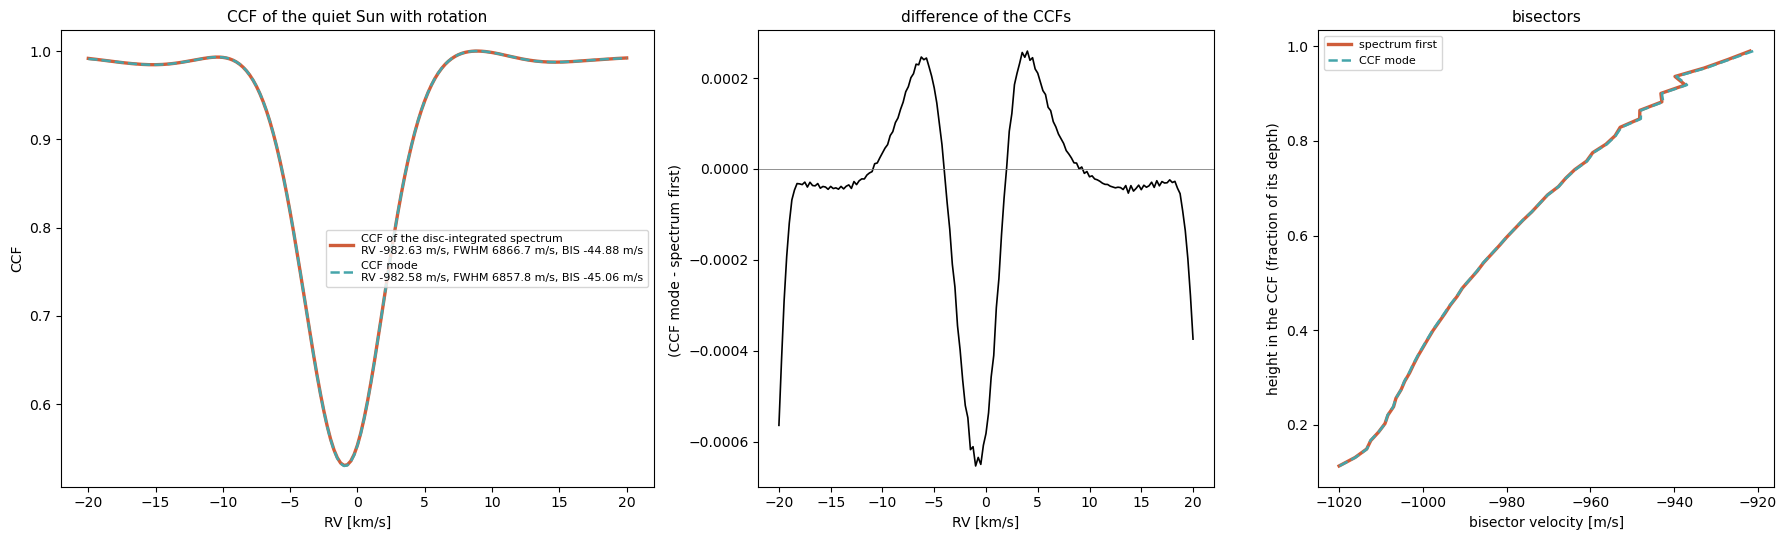

In [6]:
a, c = ccf_spectrum['rotation'], ccf_ccfmode['rotation']
r, contrast, fwhm, BIS, xbis, ybis = fits['rotation']
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={'width_ratios': [1.3, 1, 1]})
ax = axes[0]
ax.plot(rv / 1000, a/np.min(a), '-', lw=2.4, color='#cf5d3a',
        label='CCF of the disc-integrated spectrum\nRV %.2f m/s, FWHM %.1f m/s, BIS %.2f m/s' % (r[0], fwhm[0], BIS[0]))
ax.plot(rv / 1000, c/np.min(c), '--', lw=1.8, color='#45a5aa',
        label='CCF mode\nRV %.2f m/s, FWHM %.1f m/s, BIS %.2f m/s' % (r[1], fwhm[1], BIS[1]))
ax.set_xlabel('RV [km/s]')
ax.set_ylabel('CCF')
ax.set_title('CCF of the quiet Sun with rotation', fontsize=11)
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(rv / 1000, (c/np.min(c) - a/np.min(a)), '-', color='k', lw=1.2)
ax.axhline(0, color='grey', lw=0.6)
ax.set_xlabel('RV [km/s]')
ax.set_ylabel('(CCF mode - spectrum first) ')
ax.set_title('difference of the CCFs', fontsize=11)
ax = axes[2]
ax.plot(xbis[0], ybis[0], '-', lw=2.4, color='#cf5d3a', label='spectrum first')
ax.plot(xbis[1], ybis[1], '--', lw=1.8, color='#45a5aa', label='CCF mode')
ax.set_xlabel('bisector velocity [m/s]')
ax.set_ylabel('height in the CCF (fraction of its depth)')
ax.set_title('bisectors', fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Convergence with the number of rings

The quiet Sun with rotation computed with N rings, for both paths, and compared with the largest N of the same path: RV, FWHM, BIS, the contrast and the shape of the raw CCF (largest difference / depth of the CCF). Every run is a separate process (`ring_convergence.py`), so its time and its peak memory are its own. The runs are kept in `ring_convergence_results.json` and not done again. Tolerances: 0.1 m/s in RV and BIS, 1 m/s in FWHM, 1e-4 of the depth for the CCF.

In [7]:
import json
import ring_convergence as rc

N_TEST = {'ccf': [5, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80, 100], 'spectrum': [5, 8, 10, 12, 15, 20, 25, 30, 40]}
TOL = {'rv': 0.1, 'fwhm': 1.0, 'bis': 0.1, 'ccf': 1e-4}
LABEL = {'ccf': 'CCF mode', 'spectrum': 'spectrum first'}
cache = 'ring_convergence_results.json'
conv_runs = json.load(open(cache)) if os.path.exists(cache) else []
done = {(r['method'], r['N_rings']) for r in conv_runs}
for method, Ns in N_TEST.items():
    for n in Ns:
        if (method, n) not in done:
            conv_runs.append(rc.run(method, n))
            json.dump(conv_runs, open(cache, 'w'))

rows = []
for method in N_TEST:
    runs_m = sorted([r for r in conv_runs if r['method'] == method and r['N_rings'] in N_TEST[method]], key=lambda r: r['N_rings'])
    ref = runs_m[-1]
    for r in runs_m:
        c, c_ref = np.array(r['ccf']), np.array(ref['ccf'])
        rows.append({'method': LABEL[method], 'N_rings': r['N_rings'], 'cells': r['n_cells'], 'RV [m/s]': r['rv'],
                     'dRV [m/s]': r['rv'] - ref['rv'], 'dFWHM [m/s]': r['fwhm'] - ref['fwhm'], 'dBIS [m/s]': r['bis'] - ref['bis'],
                     'dcontrast / contrast': r['contrast'] / ref['contrast'] - 1,
                     'max |dCCF| / depth': np.max(np.abs(c - c_ref)) / np.ptp(c_ref),
                     'grid [s]': r['t_grid'], 'peak memory [GB]': r['peak_memory_gb']})
conv = pd.DataFrame(rows)
pd.options.display.float_format = '{:.4g}'.format
conv.set_index(['method', 'N_rings'])

cells  RV [m/s]  dRV [m/s]  dFWHM [m/s]  dBIS [m/s]  \
method         N_rings                                                        
CCF mode       5           53    -979.9      2.774       -4.304      0.4127   
               8          144    -982.1     0.6403       -2.512      0.3948   
               10         230    -982.6     0.1363       -4.018    0.005853   
               12         337    -982.5     0.1609       -3.889     -0.1522   
               15         535    -982.9     -0.171       -1.875   -0.001836   
               20         969    -982.7    0.02477      -0.4135    -0.04108   
               25        1533    -982.7  -0.002624      -0.4609     0.05954   
               30        2218    -982.7   -0.02515      -0.3149    -0.02454   
               40        3971    -982.7    0.02834     -0.08774    0.006771   
               50        6240    -982.7   -0.01196     -0.07266    -0.01083   
               60        9016    -982.7   -0.01201     -0.02774   -0.004219   
               80       16096    -982.7   -0.01008    -0.001034   -0.004754   
               100      25216    -982.7          0            0           0   
spectrum first 5           53      -980      2.692       -13.46      0.3736   
               8          144    -982.1     0.6399       -5.181      0.3375   
               10         230    -982.6     0.0949       -3.421   -0.007507   
               12         337    -982.6     0.1222       -2.927     -0.1282   
               15         535    -982.9    -0.1947       -2.213    -0.01651   
               20         969    -982.7  -0.002897      -0.4562     -0.0524   
               25        1533    -982.8   -0.03122      -0.2957     0.05456   
               30        2218    -982.8   -0.05305      -0.2477    -0.03131   
               40        3971    -982.7          0            0           0   

                        dcontrast / contrast  max |dCCF| / depth  grid [s]  \
method         N_rings                                                       
CCF mode       5                     0.01739             0.03545    0.3012   
               8                    0.006718             0.01446    0.3028   
               10                   0.003391            0.006844    0.3028   
               12                   0.002277            0.003673    0.3164   
               15                   0.001204            0.001967    0.3575   
               20                  0.0007611            0.001495    0.4172   
               25                  0.0005657            0.001143    0.4861   
               30                  0.0002709            0.000462    0.4564   
               40                  0.0002095           0.0004507    0.5617   
               50                  8.376e-05            0.000146    0.6405   
               60                  4.791e-05            8.39e-05    0.7237   
               80                   9.28e-06           1.143e-05    0.8588   
               100                         0                   0     1.016   
spectrum first 5                     0.01737             0.03508    0.2238   
               8                    0.006832             0.01404    0.2716   
               10                   0.003415            0.006408     0.293   
               12                   0.001946            0.003212    0.3126   
               15                   0.001047            0.001539    0.4128   
               20                  0.0005683            0.001047    0.5076   
               25                   0.000346           0.0006923    0.7104   
               30                  6.502e-05           5.684e-05    0.9365   
               40                          0                   0     1.559   

                        peak memory [GB]  
method         N_rings                    
CCF mode       5                  0.3854  
               8                  0.3785  
               10                 0.3662  
               12                 0.363

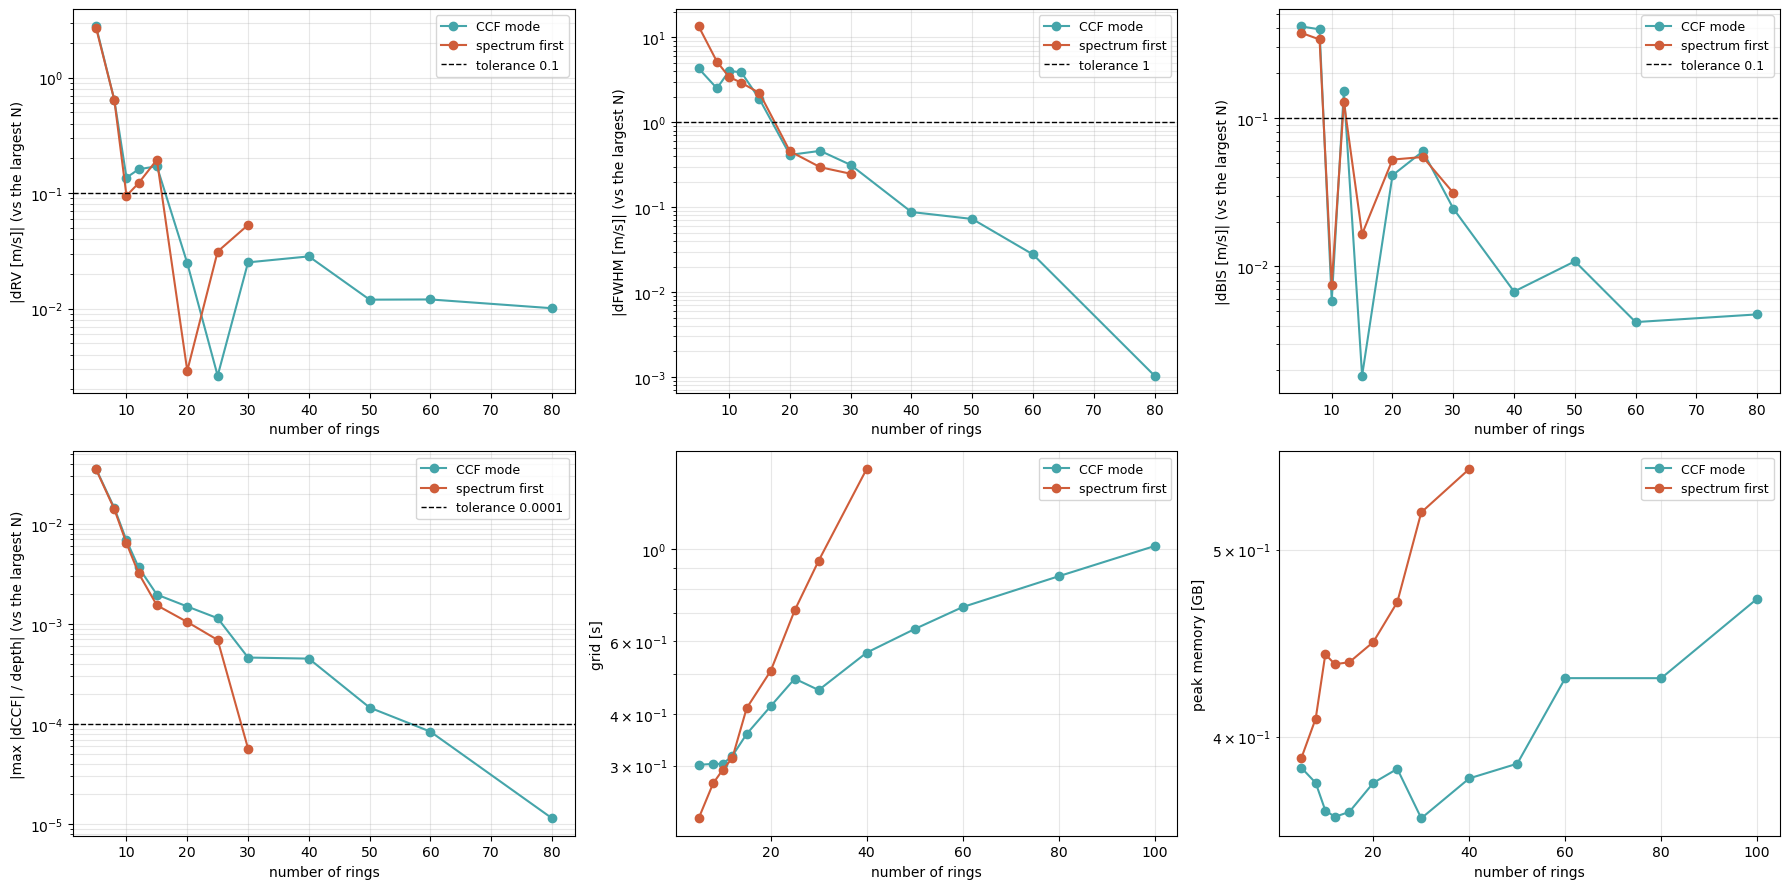

CCF mode       RV, FWHM, BIS                minimal number of rings:  20 (  969 cells, grid 0.4 s, peak memory 0.38 GB; reference 100 rings)
CCF mode       RV, FWHM, BIS and CCF shape  minimal number of rings:  60 ( 9016 cells, grid 0.7 s, peak memory 0.43 GB; reference 100 rings)
spectrum first RV, FWHM, BIS                minimal number of rings:  20 (  969 cells, grid 0.5 s, peak memory 0.45 GB; reference 40 rings)
spectrum first RV, FWHM, BIS and CCF shape  minimal number of rings:  30 ( 2218 cells, grid 0.9 s, peak memory 0.52 GB; reference 40 rings)


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
panels = [('dRV [m/s]', TOL['rv']), ('dFWHM [m/s]', TOL['fwhm']), ('dBIS [m/s]', TOL['bis']),
          ('max |dCCF| / depth', TOL['ccf']), ('grid [s]', None), ('peak memory [GB]', None)]
colors = {'CCF mode': '#45a5aa', 'spectrum first': '#cf5d3a'}
for ax, (col, tol) in zip(axes.ravel(), panels):
    for method, d in conv.groupby('method'):
        d = d[d['N_rings'] < d['N_rings'].max()] if tol is not None else d
        ax.plot(d['N_rings'], np.abs(d[col]), 'o-', color=colors[method], label=method)
    if tol is not None:
        ax.axhline(tol, color='k', ls='--', lw=1, label='tolerance %g' % tol)
        ax.set_ylabel('|%s| (vs the largest N)' % col)
    else:
        ax.set_ylabel(col)
    ax.set_yscale('log')
    ax.set_xlabel('number of rings')
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

def minimal_rings(d, keys):
    ok = np.ones(len(d), bool)
    for key, col in (('rv', 'dRV [m/s]'), ('fwhm', 'dFWHM [m/s]'), ('bis', 'dBIS [m/s]'), ('ccf', 'max |dCCF| / depth')):
        if key in keys:
            ok &= (np.abs(d[col]) < TOL[key]).values
    ok = ok[::-1].cumprod()[::-1].astype(bool)          # every larger N within the tolerances too
    return d['N_rings'].values[ok][0] if ok.any() else None

for method, d in conv.groupby('method'):
    d = d.sort_values('N_rings')
    for what, keys in (('RV, FWHM, BIS', ('rv', 'fwhm', 'bis')), ('RV, FWHM, BIS and CCF shape', ('rv', 'fwhm', 'bis', 'ccf'))):
        n = minimal_rings(d, keys)
        row = d[d['N_rings'] == n].iloc[0]
        print('%-14s %-28s minimal number of rings: %3d (%5d cells, grid %.1f s, peak memory %.2f GB; reference %d rings)'
              % (method, what, n, row['cells'], row['grid [s]'], row['peak memory [GB]'], d['N_rings'].max()))

## Conclusions of section 5 (number of rings, quiet Sun with rotation)

* **Time and memory are not a constraint** for the grid of the quiet Sun: less than 1.6 s and 0.6 GB per run at every number of rings tested (up to 100 rings, 25 216 cells, in CCF mode; 40 rings, 3971 cells, spectrum first).
* **RV, FWHM and BIS converge from 20 rings** in both paths (within 0.03 m/s in RV, 0.5 m/s in FWHM, 0.06 m/s in BIS of the largest N). Below, the errors are larger and not monotonic (the discretisation of the rings): 2.8 m/s in RV at 5 rings, 0.6 m/s at 8, 0.1-0.2 m/s at 10-15; 2-4 m/s in FWHM below 15 rings. The 10 rings of sections 1-4 are 0.14 m/s off in RV and 4 m/s in FWHM.
* **The CCF itself** (largest difference within 1e-4 of its depth) needs 60 rings in CCF mode (30 for spectrum first, compared with only 40 rings).
* **Recommendation:** at least 20 rings for RV, FWHM and BIS at the 0.1 m/s level, 30 for a margin, 60 if the shape of the CCF matters at 1e-4. These are numbers for the quiet Sun: with active regions the size of the cells compared with the regions matters too.

## Conclusions (raw CCFs, full spectrum, 10 rings)

* **Without rotation the two paths are identical** to the rounding: the raw CCFs differ by 3e-13 of their depth (RV 3e-9 m/s, FWHM 1e-8 m/s, BIS 1e-10 m/s). The CCF is linear in the spectrum, so the CCF mode with raw CCFs (`normalization='none'`) is exactly the CCF of the disc-integrated spectrum: the brightness of every ring at every line (the limb darkening, which depends on the wavelength) is in its raw CCF, with no weight to choose.
* **With rotation** (vsini 2.05 km/s, solar differential rotation): RV within 0.05 m/s, BIS within 0.18 m/s, the bisectors on top of each other, the raw CCFs within 0.14 % of their depth, and the CCF mode 8.9 m/s narrower in FWHM (0.13 %). The rotation velocities of the cells are the same in both paths; the difference is the linear interpolation of the Doppler shifts, which widens the spectra of the cells (sampled at 0.006-0.01 Å) in the spectrum-first path more than the CCFs (250 m/s) in the CCF mode: with the spectra resampled at 0.005 Å it falls to 1.4 m/s (section 4). The CCF mode is the more accurate here. Near the ends of the velocity grid (±20 km/s) the CCF mode extends the shifted ring CCFs with their end values (edge of the difference plot).
* `interpolation='ccf'` (the raw CCFs of the 10 tabulated spectra interpolated in μ, instead of the spectrum of every ring) moves the RV by 0.6 m/s here: interpolating the CCF linearly in μ is not exactly the CCF of the spectrum interpolated in μ when the lines change with μ.